# Project · Your sampler against random

Your group implements the approach of its paper as a **sampler**: a function that proposes the next trials, as in Tutorial 06. Every member plays four blocks of 100 trials; the group pools them and compares, with the same model, which data teaches the model more.

| block | label | sampler | when |
|---|---|---|---|
| 1 | `train` | random | Day 2 |
| 2 | `test` | random | Day 2 |
| 3 | `exp_train` | your sampler | project |
| 4 | `exp_test` | your sampler | project |

1. Your group
2. Your sampler
3. A simulated check
4. Play your blocks
5. The evaluation
6. Where did the trials go?
7. Discussion

You write code only in section 2. Everything else is ready-made.

## Setup

In [1]:
import os
import sys

# the course folder is one level above tutorials/
root = os.path.abspath("..")
if not os.path.isdir(os.path.join(root, "resources")):
    root = os.path.abspath(os.path.join("..", ".."))
sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from resources.gp import GP
from resources.twoafc_tools import (SimulatedPlayer, random_trials, candidate_grid, play_block,
                                    cross_validate, load_group_blocks, plot_placement)

rng = np.random.default_rng(1)

## 1. Your group
The participant IDs of all members (the 4-character IDs the task gave you).

In [2]:
GROUP = ["ABCD", "EFGH", "IJKL", "MNOP"]   # replace with your IDs
SAMPLER_FILE = "my_sampler.py"             # the file with your sampler (section 2), next to this notebook

## 2. Your sampler

Write your sampler into the file `SAMPLER_FILE` (next to this notebook), in the form of Tutorial 06:

```python
import numpy as np
from resources.twoafc_tools import candidate_grid

def my_sampler(gp, n, rng):          # or my_sampler(gp, data, n, rng) if you need the trials so far
    candidates = candidate_grid()    # or your own candidates (ratio 0.1-0.9, scatteredness 0-1)
    ...
    return next_trials               # DataFrame with n rows and the columns ratio, scatteredness
```

- `gp`: the GP fitted to all trials so far (`gp.latent`, `gp.p_blue`, `gp.rt_prediction`, `gp.information`, see Tutorial 06)
- `data`: the trials so far (ratio, scatteredness, choice_blue, rt_ms)
- `n`: how many trials to propose (10 per cycle), `rng`: a random generator

The task calls it between cycles: 20 random trials, then cycles of 10. The cell below loads it (it uses the uncertainty sampler of Tutorial 06 if the file does not exist yet).

In [3]:
import importlib.util

def load_sampler(path, name="my_sampler"):
    spec = importlib.util.spec_from_file_location("my_sampler_module", path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return getattr(module, name)

def tutorial_06_uncertainty(gp, n, rng):
    candidates = candidate_grid()
    gain = gp.information(candidates, rng=rng)["total"].to_numpy()
    return candidates.iloc[np.argsort(-gain)[:n]].reset_index(drop=True)

if os.path.exists(SAMPLER_FILE):
    my_sampler = load_sampler(SAMPLER_FILE)
    print("loaded", SAMPLER_FILE)
else:
    my_sampler = tutorial_06_uncertainty
    print(SAMPLER_FILE, "not found: using the uncertainty sampler of Tutorial 06")

my_sampler.py not found: using the uncertainty sampler of Tutorial 06


## 3. A simulated check
Before anybody plays: does your sampler run, and where does it put its trials? A simulated player plays one block of 100 trials as the task would (20 random trials, then cycles of 10), and the same again with the random sampler. The bands on top and on the right show how densely the trials cover ratio and scatteredness.

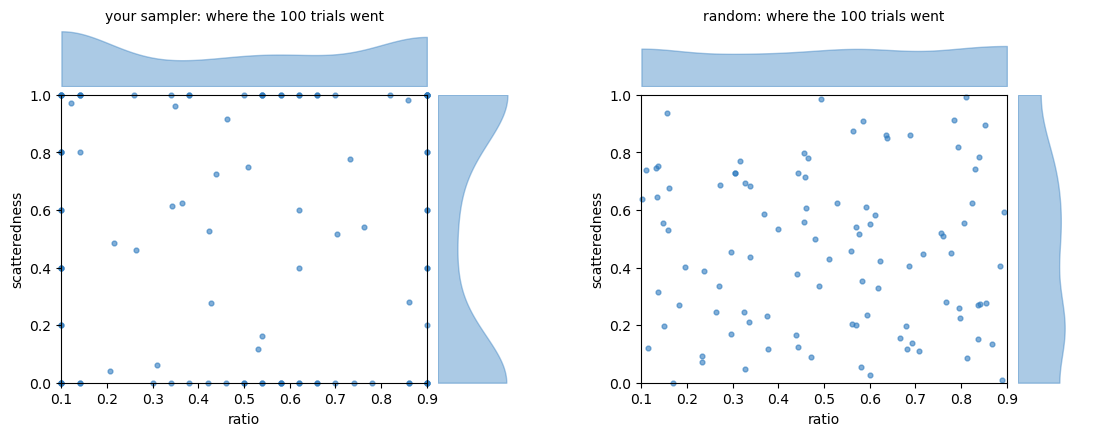

In [4]:
import inspect

def as_block_sampler(sampler):
    takes_data = "data" in inspect.signature(sampler).parameters
    def propose(data, n, rng):
        gp = GP().fit(data)
        return sampler(gp=gp, data=data, n=n, rng=rng) if takes_data else sampler(gp, n, rng)
    return propose

player = SimulatedPlayer(seed=1)
simulated = play_block(as_block_sampler(my_sampler), player, n_trials=100, n_start=20, cycle=10, rng=rng)
simulated_random = player.run(random_trials(100, rng))

plot_placement({"your sampler": simulated, "random": simulated_random});

## 4. Play your blocks
Every member plays, with their own ID, on their own computer (the task runs your sampler on the player's own trials):

```
python -m experiments.twoafc --id ABCD --block exp_train --experimentalist tutorials/my_sampler.py:my_sampler
python -m experiments.twoafc --id ABCD --block exp_test  --experimentalist tutorials/my_sampler.py:my_sampler
```

Collect all members' files (`data/twoafc/twoafc_<ID>_<block>_<time>.csv`) in `data/twoafc/` of the computer that runs this notebook.

## 5. The evaluation

The group's four blocks, pooled over the members. The **same GP** (choice and RT) is fitted on each training block and scored on each test block and on both tests together, in bits per held-out trial over the baselines (a coin flip for the choice, 'the RT is always the same' for the RT). Compare within a column.

Without your files, simulated stand-in blocks are used (marked below).

In [5]:
blocks = load_group_blocks(GROUP)

if len(blocks) < 4:
    print("\nNot all four blocks found: using simulated stand-in data for the evaluation.")
    stand_in = SimulatedPlayer(seed=2)
    n = 100 * len(GROUP)
    blocks = {"train": stand_in.run(random_trials(n, rng)), "test": stand_in.run(random_trials(n, rng)),
              "exp_train": play_block(as_block_sampler(my_sampler), stand_in, n_trials=n, n_start=20, rng=rng),
              "exp_test": play_block(as_block_sampler(my_sampler), stand_in, n_trials=n, n_start=20, rng=rng)}

train = {"random": blocks["train"], "your sampler": blocks["exp_train"]}
test = {"random": blocks["test"], "your sampler": blocks["exp_test"]}

table = {part: cross_validate(train, test, part=part) for part in ["total", "choice", "RT"]}
table["total"]

missing: ABCD train
missing: EFGH train
missing: IJKL train
missing: MNOP train
missing: ABCD test
missing: EFGH test
missing: IJKL test
missing: MNOP test
missing: ABCD exp_train
missing: EFGH exp_train
missing: IJKL exp_train
missing: MNOP exp_train
missing: ABCD exp_test
missing: EFGH exp_test
missing: IJKL exp_test
missing: MNOP exp_test

Not all four blocks found: using simulated stand-in data for the evaluation.


,random test,your sampler test,all tests
trained on random,0.799,0.712,0.755
trained on your sampler,0.846,0.685,0.765


The same table for the choice and the response time separately:

In [6]:
pd.concat({"choice": table["choice"], "RT": table["RT"]}, axis=1)

choice                                      RT  \
                        random test your sampler test all tests random test   
trained on random             0.609             0.515     0.561        0.19   
trained on your sampler       0.617             0.503     0.559        0.23   

                                                     
                        your sampler test all tests  
trained on random                   0.197     0.194  
trained on your sampler             0.182     0.206

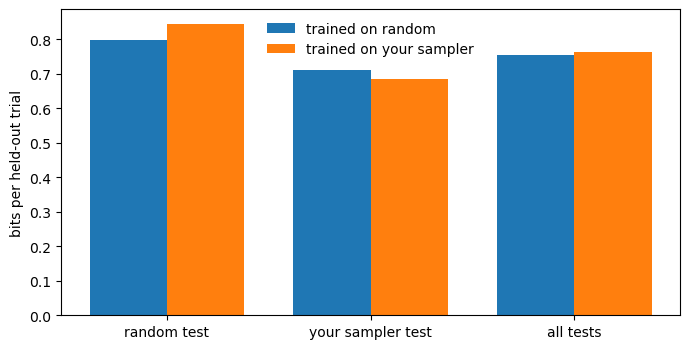

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
t = table["total"]
x = np.arange(len(t.columns))
for i, (name, row) in enumerate(t.iterrows()):
    ax.bar(x + (i - 0.5) * 0.38, row.values, width=0.38, label=name)
ax.set_xticks(x, t.columns)
ax.set_ylabel("bits per held-out trial")
ax.legend(frameon=False)
fig.tight_layout()

## 6. Where did the trials go?

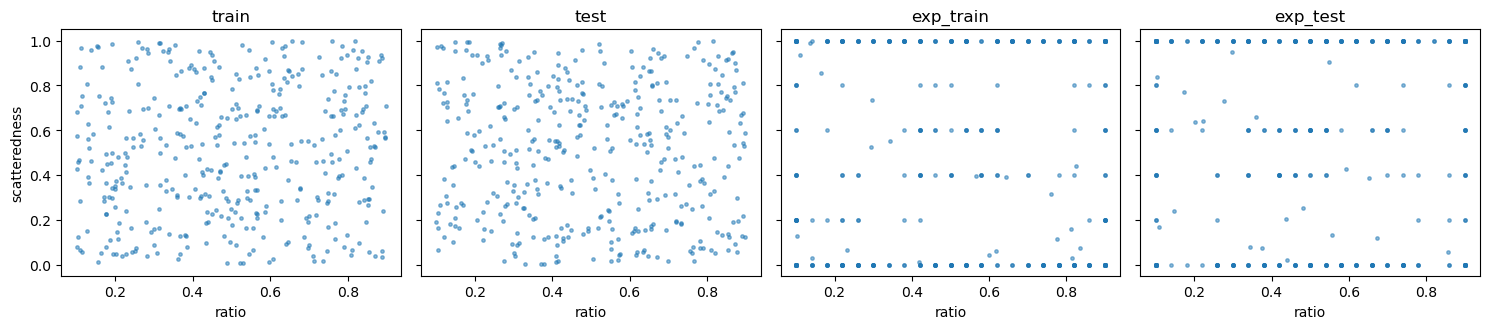

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, (name, d) in zip(axes, blocks.items()):
    ax.scatter(d["ratio"], d["scatteredness"], s=6, alpha=0.5)
    ax.set_title(name)
    ax.set_xlabel("ratio")
axes[0].set_ylabel("scatteredness")
fig.tight_layout()

## 7. Discussion

Answer in your notebook:

1. Does the model trained on your sampler's data predict better than the one trained on random data? On which test set: random, your own, both?
2. Is the difference larger than you would expect by chance? (Tutorial 06: differences of about 0.01 bits per trial can go either way.)
3. Where did your sampler put its trials, and why there? Did it behave as the paper intends?
4. What else differs between the blocks? The order was fixed (random first): practice, fatigue, a different day.
5. What would you change in the sampler, and what would you expect?